# iMAGE: comparison of three pretrained denoisers

Restormer, DnCNN, and NAFNet are compared on one fixed SIDD/PolyU paired real-noise manifest. The project owner reports instructor approval for the three-pretrained option and NAFNet.

In Colab, put the full project folder, including the untracked data directory, at MyDrive/CCS250_CompVis_Final. Select a GPU runtime and run all cells. The notebook verifies saved results by manifest and checkpoint hash; set FORCE_EVALUATION to True to recompute all three.

Caution: published Restormer and NAFNet checkpoints were trained on SIDD training images, overlapping the source collection used here. Report SIDD and PolyU separately. DnCNN's published checkpoint was trained on Gaussian noise.

In [1]:
from pathlib import Path
import os, sys
if 'COLAB_RELEASE_TAG' in os.environ:
    from google.colab import drive
    drive.mount('/content/drive')
candidates = [Path.cwd(), Path.cwd().parent, Path('/content/drive/MyDrive/CCS250_CompVis_Final')]
ROOT = next((p.resolve() for p in candidates if (p/'app').is_dir() and (p/'data/splits.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Project and data/splits.csv are required in MyDrive/CCS250_CompVis_Final')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print('Project:', ROOT)

Project: D:\CodingRelated\Codes.Ams\ComVisFinal\CCS250_CompVis_Final


In [2]:
import subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT/'requirements.txt')])
import csv, hashlib, json
import pandas as pd
import torch
from app.experiments import dataset_counts, evaluate_model
from app.models import NAMES
from app.online import get_active_checkpoint
print('Device:', 'cuda' if torch.cuda.is_available() else 'cpu')

Device: cpu


C:\Users\heral\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
manifest = ROOT/'data/splits.csv'
counts = dataset_counts(manifest)
assert counts == {'train': 4000, 'val': 500, 'test': 500}
manifest_sha256 = hashlib.sha256(manifest.read_bytes()).hexdigest()
print('Split counts:', counts)
print('Manifest SHA-256:', manifest_sha256)
with manifest.open(newline='', encoding='utf8') as f:
    rows = list(csv.DictReader(f))
print(pd.crosstab(pd.Series([r['source'] for r in rows],name='source'), pd.Series([r['split'] for r in rows],name='split')))

Split counts: {'train': 4000, 'val': 500, 'test': 500}
Manifest SHA-256: 49116dee666c137f25bc76db5196326c5e64db20ce3ae9cd755b3f3e79b689e2
split   test  train  val
source                  
PolyU    150   1200  150
SIDD     350   2800  350


## Validation choice

A 200-step DnCNN fine-tuning trial reduced 50-crop validation PSNR from 35.54 to 32.26 dB. The final comparison therefore uses the published DnCNN checkpoint. The trial checkpoint and measurements are in HeraldFolder. Older saved outputs in development notebook 03 use a different manifest and are excluded.

In [4]:
for name in NAMES:
    checkpoint = get_active_checkpoint(name)
    print(name, checkpoint.name, hashlib.sha256(checkpoint.read_bytes()).hexdigest())
trial = ROOT/'HeraldFolder/dncnn_finetune_trial.json'
if trial.is_file():
    print(json.loads(trial.read_text(encoding='utf8'))['selection'])

restormer restormer_real.pth 4cae18bed8a291b9a5deeeab48756bbe6f61fcf7f31a4cca0969b24608601387
dncnn dncnn.pth dfe11a6b703304df82cdf236f431fc6492766c7b9119d97e943edeb392c710a3


nafnet NAFNet-SIDD-width32.pth 89c70e808d1783b6c07911306e106aaf0d4f7f3da8c61078b99ff7f8929a26f4
published DnCNN baseline retained because trial validation PSNR decreased from 35.53753 to 32.26428 dB on the same 50 crops


## Shared test

All three methods use the same 500 test rows and 64 by 64 RGB center crops. PSNR and SSIM use a data range of 1. Runtime covers forward inference. Saved results are reused only when the manifest, checkpoint, crop, and sample count match; set FORCE_EVALUATION to True to rerun.

In [5]:
FORCE_EVALUATION = False
out = ROOT/'HeraldFolder/test'
out.mkdir(parents=True, exist_ok=True)
if not torch.cuda.is_available():
    torch.set_num_threads(4)
summaries = []
for name in NAMES:
    checkpoint = get_active_checkpoint(name)
    summary_file = out/f'{name}_summary.json'
    valid_cache = False
    if summary_file.is_file():
        old = json.loads(summary_file.read_text(encoding='utf8'))
        valid_cache = (old.get('manifest_sha256') == manifest_sha256
                       and old.get('checkpoint_sha256') == hashlib.sha256(checkpoint.read_bytes()).hexdigest()
                       and old.get('number_of_test_images') == 500
                       and old.get('patch') == 64 and old.get('tile') == 64)
    if FORCE_EVALUATION or not valid_cache:
        print('Evaluating', name)
        summary = evaluate_model(name, patch=64, tile=64, output_dir=out)
    else:
        print('Verified saved result:', name)
        summary = old
    summaries.append(summary)

Verified saved result: restormer
Verified saved result: dncnn


Verified saved result: nafnet


In [6]:
assert len(summaries) == 3
assert all(s['number_of_test_images'] == 500 and not s['limited_test'] for s in summaries)
assert len({s['manifest_sha256'] for s in summaries}) == 1
frame = pd.DataFrame([{'model':s['model'], 'PSNR (dB)':s['psnr_db'], 'SSIM':s['ssim'],
                       'runtime (ms/crop)':s['mean_runtime_ms'], 'parameters (M)':s['parameters_m'],
                       'SIDD PSNR':s['by_source']['SIDD']['psnr_db'],
                       'PolyU PSNR':s['by_source']['PolyU']['psnr_db']} for s in summaries])
display(frame.round(3))
best = max(summaries, key=lambda s: s['by_source']['PolyU']['psnr_db'])
print('Highest PolyU PSNR:', best['model'])

,model,PSNR (dB),SSIM,runtime (ms/crop),parameters (M),SIDD PSNR,PolyU PSNR
0,restormer,42.578,0.975,292.31,26.112,43.653,40.068
1,dncnn,34.114,0.779,25.76,0.668,32.548,37.768
2,nafnet,42.506,0.972,42.25,29.160,43.963,39.106


Highest PolyU PSNR: restormer


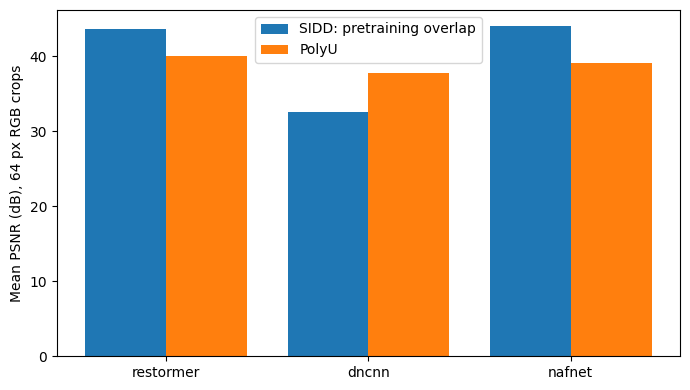

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
positions = range(len(frame))
ax.bar([x-0.2 for x in positions], frame['SIDD PSNR'], width=0.4, label='SIDD: pretraining overlap')
ax.bar([x+0.2 for x in positions], frame['PolyU PSNR'], width=0.4, label='PolyU')
ax.set_xticks(list(positions), frame['model'])
ax.set_ylabel('Mean PSNR (dB), 64 px RGB crops')
ax.legend()
fig.tight_layout()
fig.savefig(out/'comparison_by_source.png', dpi=160)
display(fig)
plt.close(fig)

## Reproducibility and limits

The 5,000 paired images come from the SIDD and PolyU sources linked in README.md. Scene grouping prevents overlap among this project's splits, but does not remove overlap with published SIDD pretraining. Published pretraining times are unavailable. The DnCNN trial time is recorded separately. The upload app uses labeled preview filters by default; IMAGE_MODE=real enables the actual networks.